In [6]:
%pip install -q "torch>=2.6,<3" "transformers==5.12.1" "datasets>=4,<6" "accelerate>=1.2,<2" "scikit-learn>=1.5,<2" "pandas>=2.2,<4" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "ipywidgets>=8,<9"


In [7]:
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import html
import math
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)


In [8]:
SEED = 42
MODEL_NAME = "google-bert/bert-base-uncased"
TRAIN_SAMPLES = 15_000
VALIDATION_SAMPLES = 1_500
TEST_SAMPLES = 3_000
MAX_LENGTH = 128
BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4
EPOCHS = 3
LEARNING_RATE = 2e-5

ID2LABEL = {0: "Negative", 1: "Neutral", 2: "Positive"}
LABEL2ID = {name: idx for idx, name in ID2LABEL.items()}
# Original labels 0..4 mean 1..5 stars; 3 stars is our neutral proxy.
LABEL_MAP = {0: 0, 1: 0, 2: 1, 3: 2, 4: 2}
set_seed(SEED)


In [9]:
dataset = load_dataset("Yelp/yelp_review_full")


README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [10]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = text.replace("\\n", " ").replace("\\t", " ")
    return re.sub(r"\s+", " ", text).strip()


def prepare_pool(split, sample_size):
    pool_size = min(2 * sample_size, len(split))
    if pool_size < len(split):
        split = split.train_test_split(
            train_size=pool_size,
            stratify_by_column="label",
            seed=SEED,
        )["train"]

    frame = split.to_pandas()
    frame["text"] = frame["text"].map(clean_text)
    frame["label"] = frame["label"].map(LABEL_MAP)
    frame = frame.loc[frame["text"].str.len() > 0].copy()
    frame["text_key"] = frame["text"].str.casefold()
    consistent = frame.groupby("text_key")["label"].transform("nunique").eq(1)
    return frame.loc[consistent].drop_duplicates("text_key").reset_index(drop=True)


def sample_frame(frame, size):
    if size == len(frame):
        return frame.sample(frac=1, random_state=SEED).reset_index(drop=True)
    selected, _ = train_test_split(
        frame, train_size=size, stratify=frame["label"], random_state=SEED
    )
    return selected.reset_index(drop=True)


In [11]:
train_pool = prepare_pool(dataset["train"], TRAIN_SAMPLES + VALIDATION_SAMPLES)
test_pool = prepare_pool(dataset["test"], TEST_SAMPLES)
test_pool = test_pool.loc[~test_pool["text_key"].isin(train_pool["text_key"])].copy()

development_df = sample_frame(train_pool, TRAIN_SAMPLES + VALIDATION_SAMPLES)
train_df, validation_df = train_test_split(
    development_df,
    test_size=VALIDATION_SAMPLES,
    stratify=development_df["label"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = sample_frame(test_pool, TEST_SAMPLES)

assert set(train_df["text_key"]).isdisjoint(validation_df["text_key"])
assert set(development_df["text_key"]).isdisjoint(test_df["text_key"])
print({"train": len(train_df), "validation": len(validation_df), "test": len(test_df)})


{'train': 15000, 'validation': 1500, 'test': 3000}


In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def encode_frame(frame):
    split = Dataset.from_pandas(frame[["text", "label"]], preserve_index=False)
    split = split.rename_column("label", "labels")
    return split.map(tokenize_batch, batched=True, remove_columns=["text"])

train_data = encode_frame(train_df)
validation_data = encode_frame(validation_df)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

In [13]:
def compute_metrics(result):
    predictions = np.argmax(result.predictions, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        result.label_ids,
        predictions,
        labels=list(ID2LABEL),
        average="macro",
        zero_division=0,
    )
    return {
        "accuracy": float(accuracy_score(result.label_ids, predictions)),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
    }


In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [15]:
updates_per_epoch = math.ceil(
    math.ceil(len(train_data) / BATCH_SIZE) / GRADIENT_ACCUMULATION_STEPS
)
training_args = TrainingArguments(
    output_dir="bert_checkpoints",
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    weight_decay=0.01,
    warmup_steps=math.ceil(updates_per_epoch * EPOCHS * 0.1),
    optim="adamw_torch",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=25,
    report_to="none",
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=0,
    dataloader_pin_memory=torch.cuda.is_available(),
    seed=SEED,
    data_seed=SEED,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=validation_data,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
print("Device:", training_args.device)
trainer.train()


Device: cuda:0


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,2.414324,0.541452,0.768000,0.719713,0.717778,0.718442
2,1.710255,0.545494,0.774000,0.727914,0.727222,0.727366
3,1.149512,0.665449,0.770000,0.721960,0.721667,0.721804


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=2814, training_loss=1.854853377921749, metrics={'train_runtime': 697.1324, 'train_samples_per_second': 64.55, 'train_steps_per_second': 4.037, 'total_flos': 2927482108584768.0, 'train_loss': 1.854853377921749, 'epoch': 3.0})

In [16]:
test_data = encode_frame(test_df)
test_output = trainer.predict(test_data)
y_true = test_output.label_ids
y_pred = np.argmax(test_output.predictions, axis=-1)

print(pd.Series(compute_metrics(test_output)).round(4).to_string())
print(classification_report(
    y_true,
    y_pred,
    labels=list(ID2LABEL),
    target_names=list(ID2LABEL.values()),
    digits=4,
    zero_division=0,
))


Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

accuracy           0.7740
precision_macro    0.7281
recall_macro       0.7275
f1_macro           0.7278
              precision    recall  f1-score   support

    Negative     0.8280    0.8425    0.8352      1200
     Neutral     0.5042    0.4950    0.4996       600
    Positive     0.8521    0.8450    0.8485      1200

    accuracy                         0.7740      3000
   macro avg     0.7281    0.7275    0.7278      3000
weighted avg     0.7729    0.7740    0.7734      3000



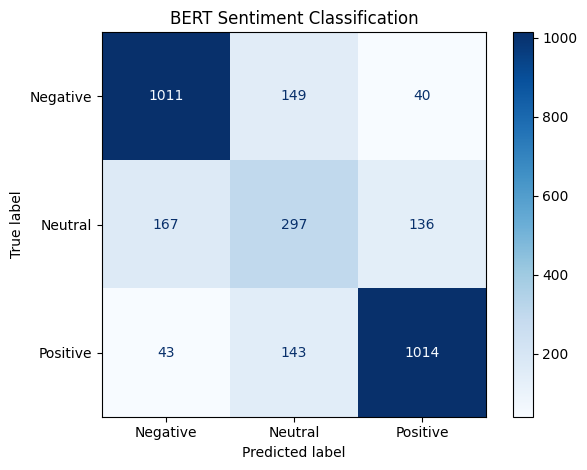

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(ID2LABEL),
    display_labels=list(ID2LABEL.values()),
    cmap="Blues",
    values_format="d",
)
plt.title("BERT Sentiment Classification")
plt.tight_layout()
plt.show()


In [18]:
trainer.save_model("bert_sentiment_model")
tokenizer.save_pretrained("bert_sentiment_model")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('bert_sentiment_model/tokenizer_config.json',
 'bert_sentiment_model/tokenizer.json')